## Feature Selection Methods 

### SKLearn  SelectKBest (using statistical tests on features)

In [ ]:
%matplotlib inline

import seaborn as sns
import pandas as pd
import numpy as np

from scipy.stats import zscore
from sklearn import metrics

from sklearn.tree import DecisionTreeClassifier


In [ ]:
# load data
colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
pima_df_full = pd.read_csv("c:\DSE\Data\pima-indians-diabetes.data", names= colnames)

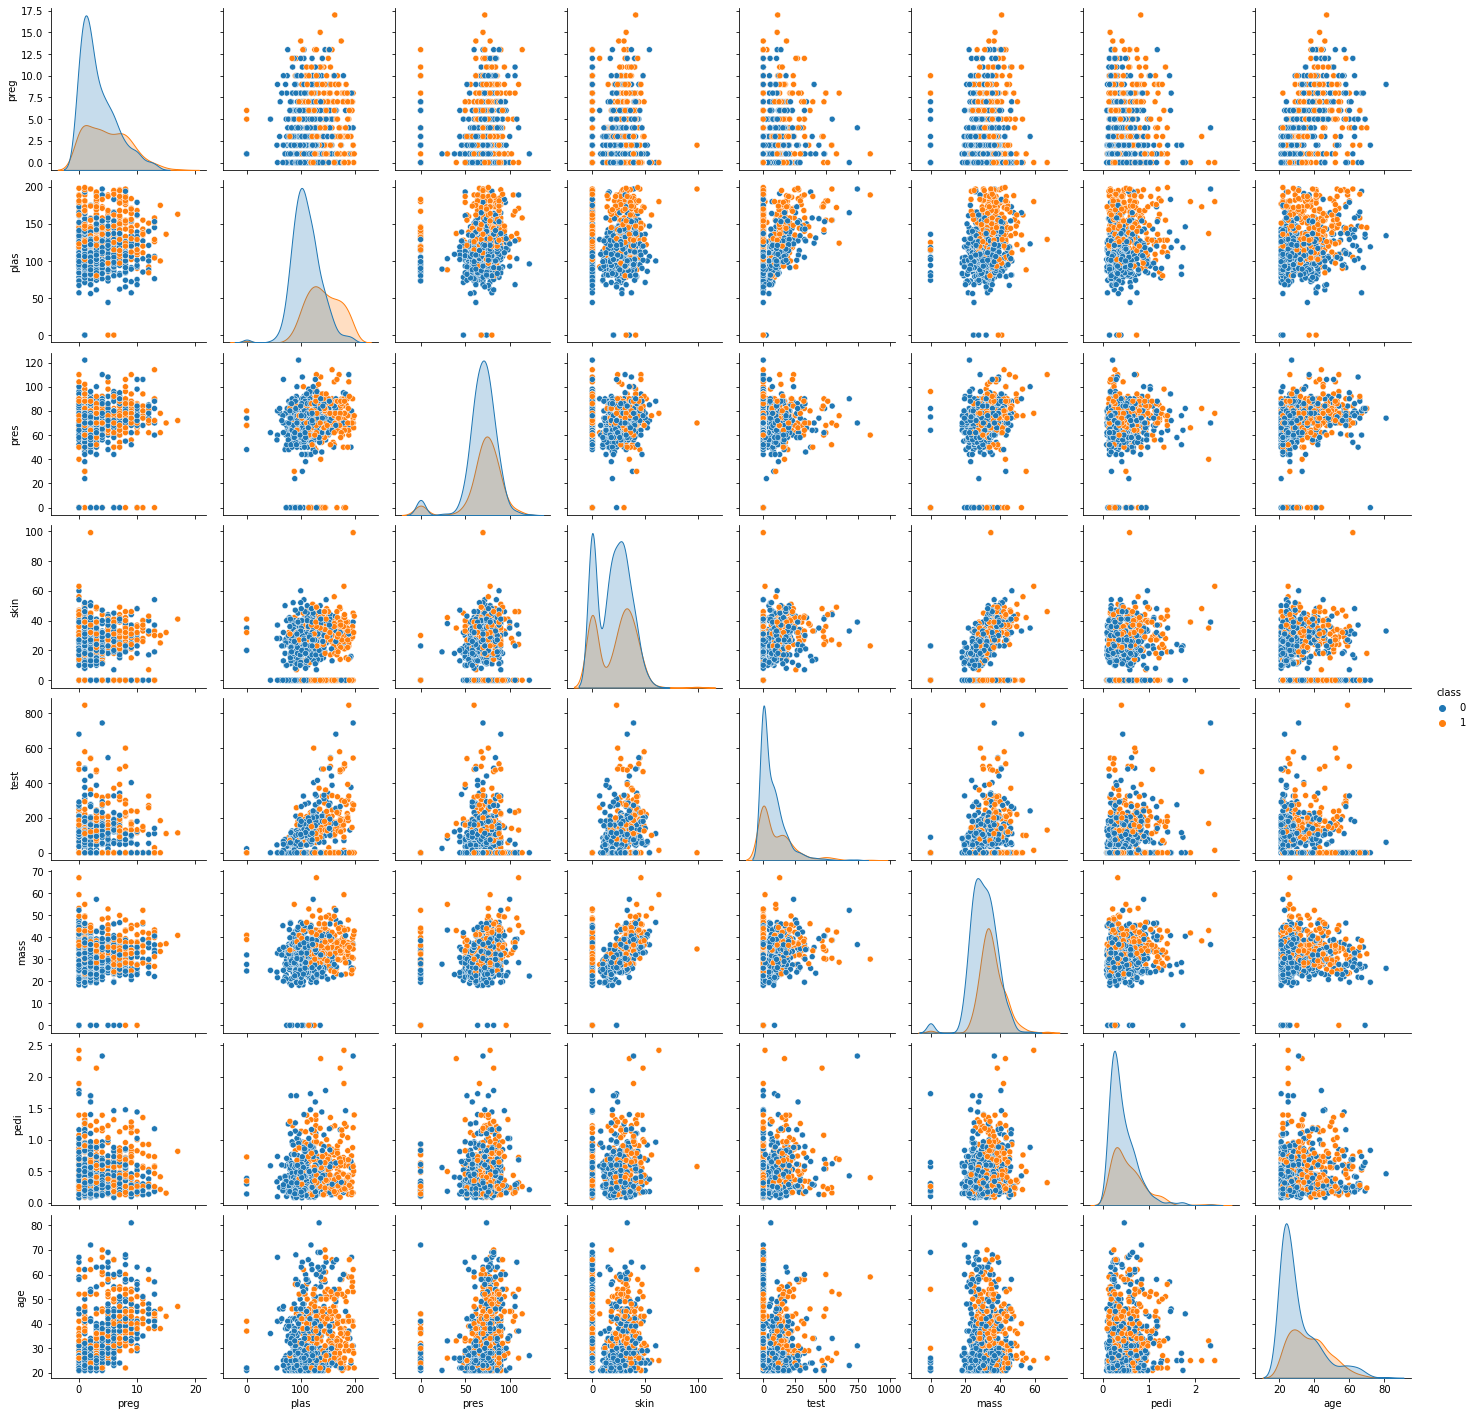

In [ ]:
sns.pairplot(data=pima_df_full, diag_kind = 'kde', hue = 'class')

# Missing value / Outlier Treatement

Steps -
1. are there missing values? If yes, are these missing at randompor missing deliberately (difficult to check but assume random)
2. Replace the missing values with numpy Nan. This way these values will be avoided for any calculation of central values
3. Use a strategy to replace missing values with appropriate values
4. check the impact of the strategy on the distribution


In [ ]:
# Are there missing values. Values may be missing but instead of blank you may find a numeric default such as 0

print((pima_df_full[['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']] == 0).sum())

plas       5
pres      35
skin     227
test     374
mass      11
pedi       0
age        0
class    500
dtype: int64


In [ ]:
pima_df_full[['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']] = pima_df_full[['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']].replace(0, np.NaN)
print((pima_df_full[['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']] == 0).sum())



plas    0
pres    0
skin    0
test    0
mass    0
pedi    0
age     0
dtype: int64


In [ ]:
pima_df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    763 non-null    float64
 2   pres    733 non-null    float64
 3   skin    541 non-null    float64
 4   test    394 non-null    float64
 5   mass    757 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


In [ ]:
# Split the data into training / testing - Always keep a part of the data separate for final testing

from sklearn.model_selection import train_test_split

pima_df_train, pima_df_test, y_train, y_test = train_test_split(pima_df_full.iloc[:,0:8] , pima_df_full.iloc[:,8] , test_size=0.30, random_state=1)

In [ ]:
# After splitting the test set, how much data from each class do we have to train model on?

print(y_train[y_train==1].count())
print(y_train[y_train==0].count())

183
354


In [ ]:
# Concatenate the target column back to the training dataframe for data cleansing classwise

pima_df_train['class'] = y_train

In [ ]:
pima_df_train

,preg,plas,pres,skin,test,mass,pedi,age,class
88,15,136.0,70.0,32.0,110.0,37.1,0.153,43,1
467,0,97.0,64.0,36.0,100.0,36.8,0.600,25,0
550,1,116.0,70.0,28.0,NaN,27.4,0.204,21,0
147,2,106.0,64.0,35.0,119.0,30.5,1.400,34,0
481,0,123.0,88.0,37.0,NaN,35.2,0.197,29,0
...,...,...,...,...,...,...,...,...,...
645,2,157.0,74.0,35.0,440.0,39.4,0.134,30,0
715,7,187.0,50.0,33.0,392.0,33.9,0.826,34,1
72,13,126.0,90.0,NaN,NaN,43.4,0.583,42,1
235,4,171.0,72.0,NaN,NaN,43.6,0.479,26,1


In [ ]:
# Separate the data for the two classes so that we can do class level missing value and outlier analysis

pima_df_nd = pima_df_train[pima_df_train['class']==0]
pima_df_d = pima_df_train[pima_df_train['class']==1]

nd_train_y = pima_df_nd['class']     # store the class values in a separate array that will will convert to dataframe below
d_train_y = pima_df_d['class']

# we will need the dataframe created below after imputing missing values and handling the outliers. 
train_y = pd.DataFrame(np.append(nd_train_y , d_train_y, axis=0))   

# Note that in the train_y the non-diabetic block comes first followed by the diabetic block. We have to makes sure
# the data representing the predictors are also arranged similarly.

In [ ]:
# Ensure the shape of the resulting two dataframes for the respective classes are as per expectataions...

print(pima_df_nd.shape)
print(pima_df_d.shape)


(354, 9)
(183, 9)


In [ ]:
# Impute missing values using imputer class. This is the safest way to address missing values, especially in classification


from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='median')  # Central values can be mean or median. Median is better as 
                                                                 # the mean is impacted by outliers which we have not addressed

In [ ]:


# Imputing classwise


imputed_pima_df_nd = imputer.fit_transform(pima_df_nd)   # creates array on transformation

imputed_pima_df_d = imputer.fit_transform(pima_df_d)   # creates array on transformation

# Since array elements are all of same type, the result of imputation is that the class column too gets converted to 
# numeric float data type transforming the labels from 0 to 0.0 and 1 to 1.0
# Classification modelling algorithms do not expect the class column to be of type float. They will give runtime error

# To avoid this, will will copy back the original version of the 'Class' column to the dataframe after imputations. Makesure you
# do not sort the data anywhere


In [ ]:
# combine the two resulting array 

imputed_pima_array = np.concatenate([imputed_pima_df_nd , imputed_pima_df_d] , axis=0)

# Remember we have to cocantenate such that non-defaulter block comes first followed by defaulter block

In [ ]:
# convert the array to a dataframe
colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
imputed_pima_df = pd.DataFrame(imputed_pima_array, columns = colnames)

In [ ]:
imputed_pima_df.head()    # Note the datatype of the "Class" 

,preg,plas,pres,skin,test,mass,pedi,age,class
0,0.0,97.0,64.0,36.0,100.0,36.8,0.600,25.0,0
1,1.0,116.0,70.0,28.0,100.0,27.4,0.204,21.0,0
2,2.0,106.0,64.0,35.0,119.0,30.5,1.400,34.0,0
3,0.0,123.0,88.0,37.0,100.0,35.2,0.197,29.0,0
4,1.0,143.0,84.0,23.0,310.0,42.4,1.076,22.0,0


In [ ]:
# Note:  The target column 'class' has  become a floating type. Not good for classification
# The first block is class 0 and next is 1

# we will copy back the saved y labels to this column

train_y = pd.DataFrame(np.append(nd_train_y , d_train_y, axis=0))


imputed_pima_df['class'] = train_y    # Overwrite the "Class" column with the stored 'Class' to restore the datatype


In [ ]:
imputed_pima_df.head()    # Note the data type of the'Class' now

,preg,plas,pres,skin,test,mass,pedi,age,class
0,0.0,97.0,64.0,36.0,100.0,36.8,0.600,25.0,0
1,1.0,116.0,70.0,28.0,100.0,27.4,0.204,21.0,0
2,2.0,106.0,64.0,35.0,119.0,30.5,1.400,34.0,0
3,0.0,123.0,88.0,37.0,100.0,35.2,0.197,29.0,0
4,1.0,143.0,84.0,23.0,310.0,42.4,1.076,22.0,0


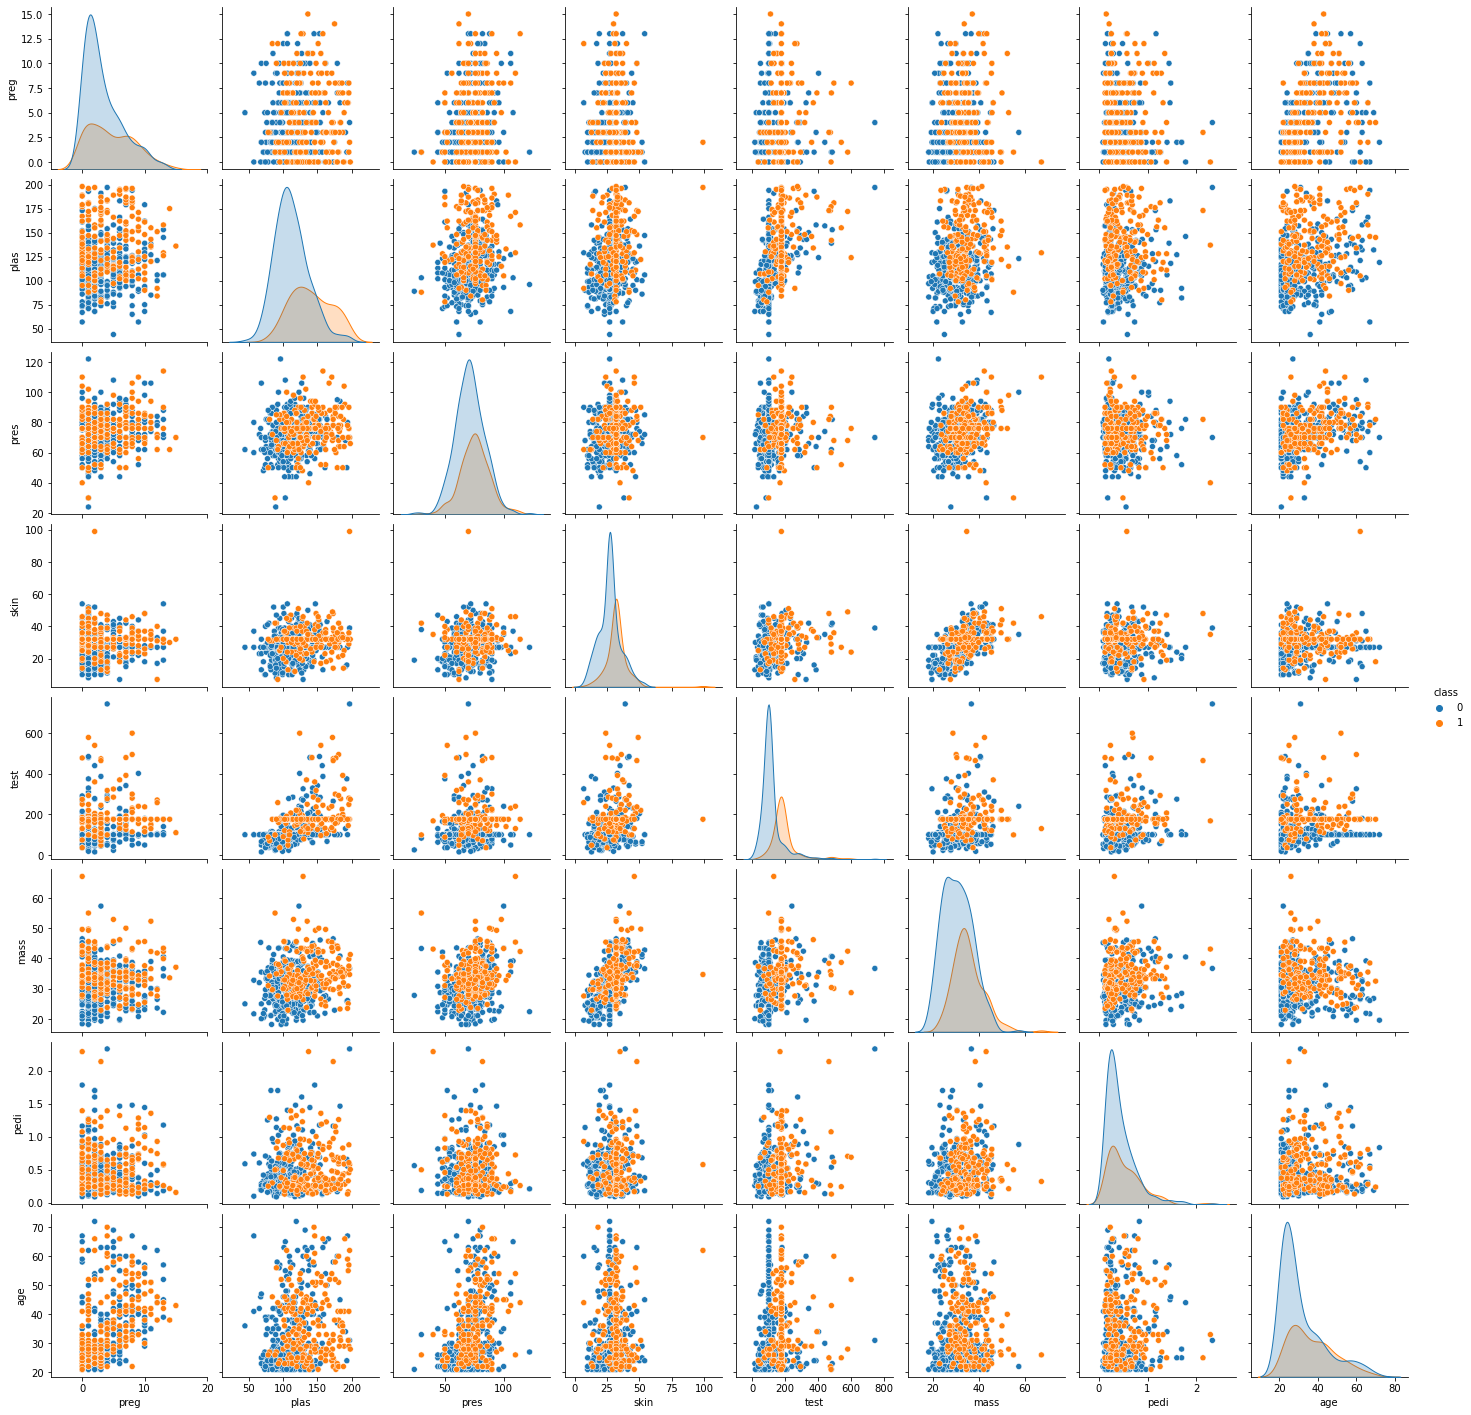

In [ ]:
sns.pairplot(data=imputed_pima_df, diag_kind = 'kde' , hue = 'class')

In [ ]:

print((imputed_pima_df[['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']] == np.NaN ).sum())

plas    0
pres    0
skin    0
test    0
mass    0
pedi    0
age     0
dtype: int64


# Let us build a regularized decision tree model and check the impact

In [ ]:
pima_df_train, pima_df_test, y_train, y_test = train_test_split(imputed_pima_df.iloc[:,0:8] , imputed_pima_df.iloc[:,8] , test_size=0.30, random_state=1)

In [ ]:
dt_model = DecisionTreeClassifier(criterion = 'entropy', max_depth=3)
dt_model.fit(pima_df_train, y_train)
y_predict = dt_model.predict(pima_df_train)

In [ ]:
print(metrics.classification_report(y_train, y_predict))      # Observe the Diabetic class metric 

              precision    recall  f1-score   support

           0       0.94      0.85      0.89       250
           1       0.75      0.90      0.82       125

    accuracy                           0.87       375
   macro avg       0.85      0.87      0.86       375
weighted avg       0.88      0.87      0.87       375



## Imputing the entire data in one shot instead of classwise....  We will not use this

In [ ]:
imputed_pima_df_all_array = imputer.fit_transform(pima_df_full) 

imputed_pima_df_all = pd.DataFrame(imputed_pima_df_all_array , columns=colnames)

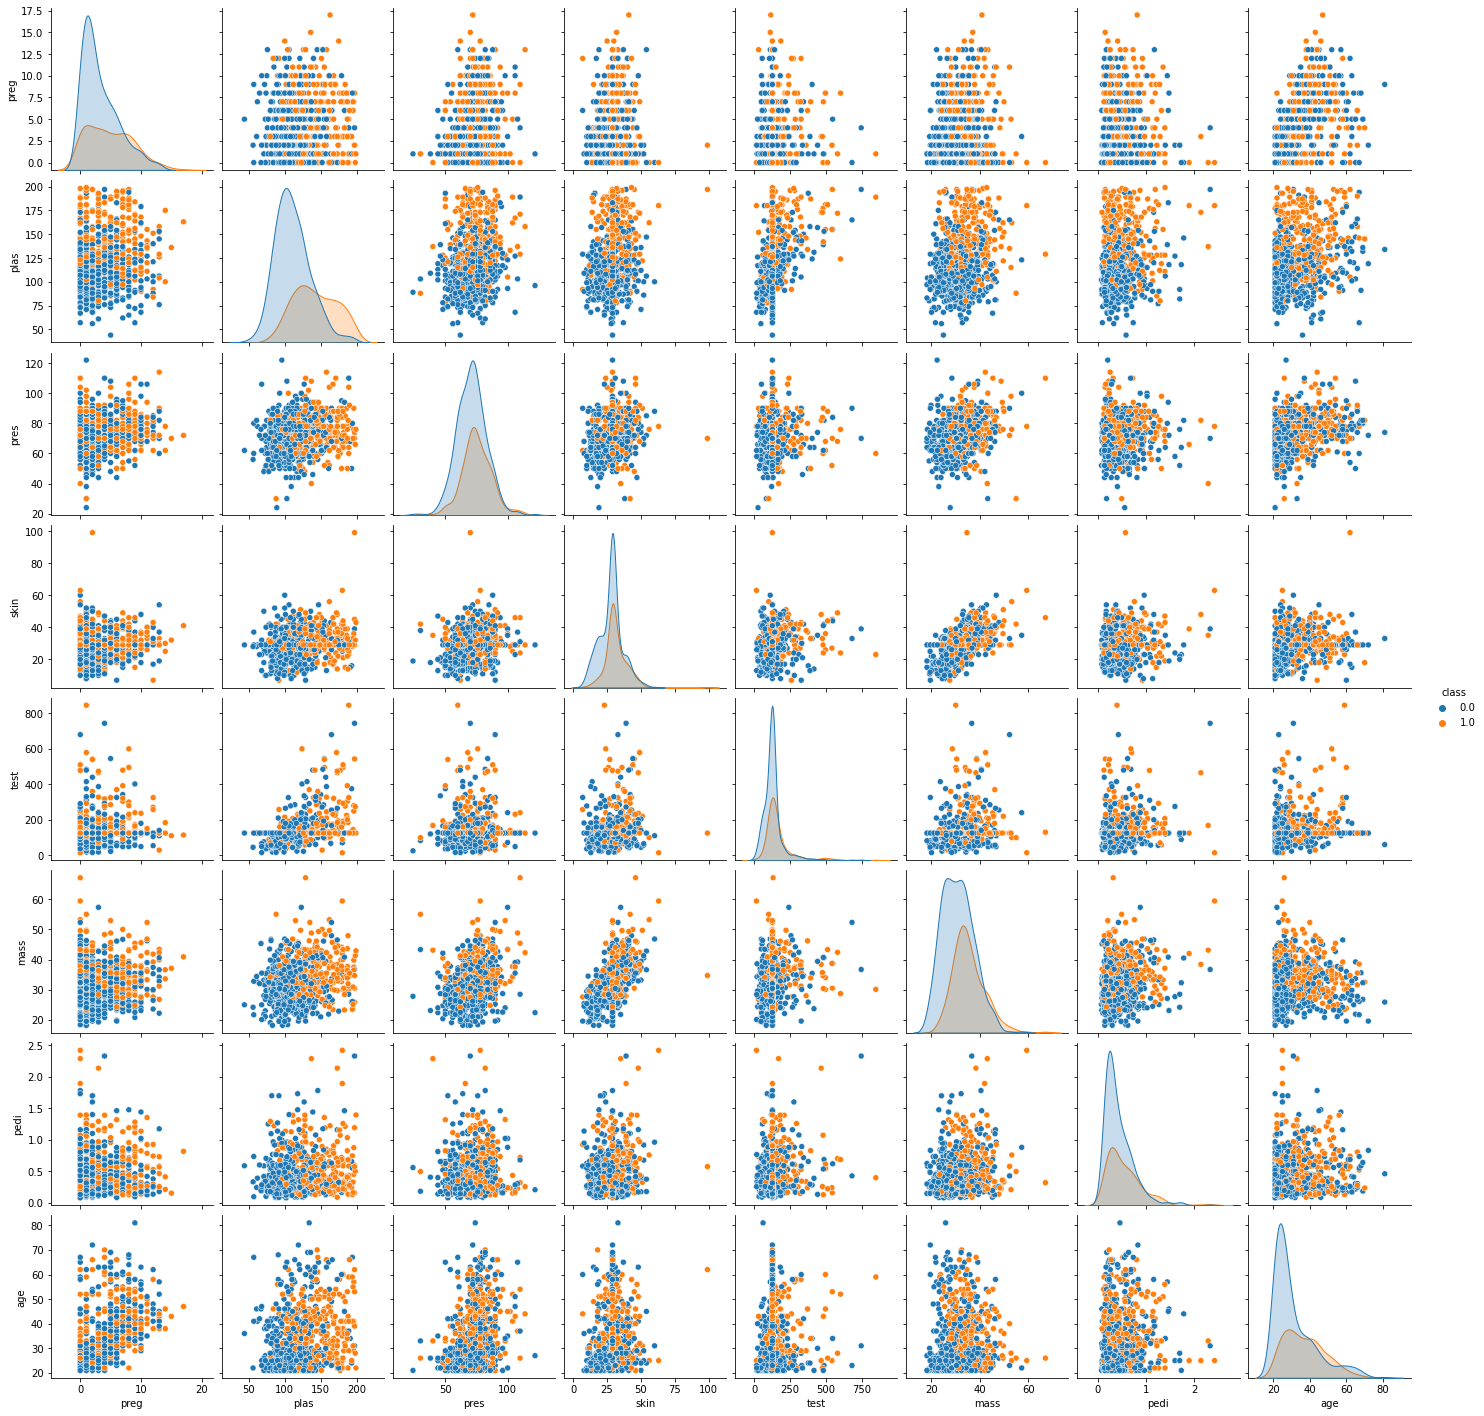

In [ ]:
sns.pairplot(data=imputed_pima_df_all, diag_kind = 'kde', hue = 'class')  # Check the distribution after the imputation

In [ ]:
pima_df_train, pima_df_test, y_train, y_test = train_test_split(imputed_pima_df_all.iloc[:,0:8] , imputed_pima_df_all.iloc[:,8] , test_size=0.30, random_state=1)

In [ ]:
dt_model = DecisionTreeClassifier(criterion = 'entropy', max_depth=3)
dt_model.fit(pima_df_train, y_train)
y_predict = dt_model.predict(pima_df_train)

In [ ]:
print(metrics.classification_report(y_train, y_predict))    # Observe the Diabetic class metric 

              precision    recall  f1-score   support

         0.0       0.79      0.86      0.83       354
         1.0       0.68      0.57      0.62       183

    accuracy                           0.76       537
   macro avg       0.74      0.72      0.72       537
weighted avg       0.76      0.76      0.76       537



### Outlier Analysis and treatement

array([[<AxesSubplot:title={'center':'age'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'mass'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'pedi'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'plas'}, xlabel='[class]'>],
       [<AxesSubplot:title={'center':'preg'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'pres'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'skin'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'test'}, xlabel='[class]'>]],
      dtype=object)

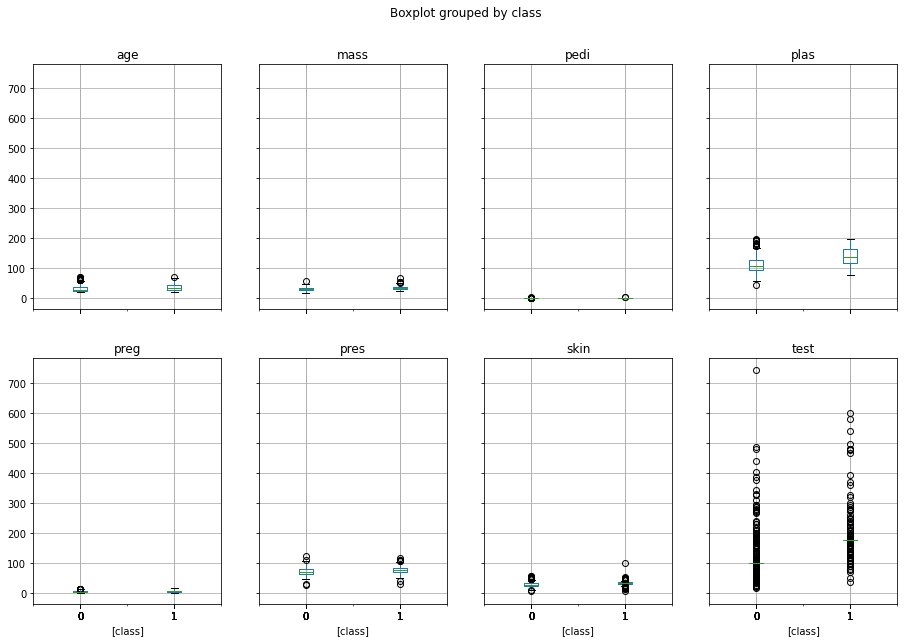

In [ ]:
imputed_pima_df.boxplot(by = 'class', layout=(2,4), figsize=(15, 10))

## Address all outliers with median classwise

In [ ]:
# Outlier fix function takes the data frame for diabetic and non-diabetic separately and looks for outliers only on the 
# select columns. It finds all values beyond 2 std dev as outliers and replaces them with the median of the variable classwise


def outlierfix(df):
    for col in ['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']:
        stddev = df[col].std()
        med = df[col].median()
        var = (df[col] - med).abs()
        df[col] = np.where(var > (2*stddev), med , df[col] )
    
    return(df)

    



In [ ]:
# Splitting the imputed dataframe (imputed for missing values earlier) into classwise sets

imputed_pima_df_nd = imputed_pima_df[imputed_pima_df['class']==0]
imputed_pima_df_d = imputed_pima_df[imputed_pima_df['class']==1]


# Call the outlierfix function on each of the two classes separately

imputed_pima_df_nd = outlierfix(imputed_pima_df_nd)
imputed_pima_df_d = outlierfix(imputed_pima_df_d)


# Following is only a list of warning..... not error

<ipython-input-29-b041f4160eb7>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = np.where(var > (2*stddev), med , df[col] )
<ipython-input-29-b041f4160eb7>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = np.where(var > (2*stddev), med , df[col] )
<ipython-input-29-b041f4160eb7>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyda

In [ ]:
# Combine the two class datasets back into one. This dataframe now has both missing values and outliers fixed classwise

final_pima_df = np.concatenate([imputed_pima_df_nd , imputed_pima_df_d] , axis=0)
final_pima_df = pd.DataFrame(final_pima_df, columns = colnames)

final_pima_df['class'] = train_y

In [ ]:
final_pima_df.head()

,preg,plas,pres,skin,test,mass,pedi,age,class
0,0.0,97.0,64.0,36.0,100.0,36.8,0.6000,25.0,0
1,1.0,116.0,70.0,28.0,100.0,27.4,0.2040,21.0,0
2,2.0,106.0,64.0,35.0,119.0,30.5,0.3295,34.0,0
3,0.0,123.0,88.0,37.0,100.0,35.2,0.1970,29.0,0
4,1.0,143.0,84.0,23.0,100.0,42.4,0.3295,22.0,0


array([[<AxesSubplot:title={'center':'age'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'mass'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'pedi'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'plas'}, xlabel='[class]'>],
       [<AxesSubplot:title={'center':'preg'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'pres'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'skin'}, xlabel='[class]'>,
        <AxesSubplot:title={'center':'test'}, xlabel='[class]'>]],
      dtype=object)

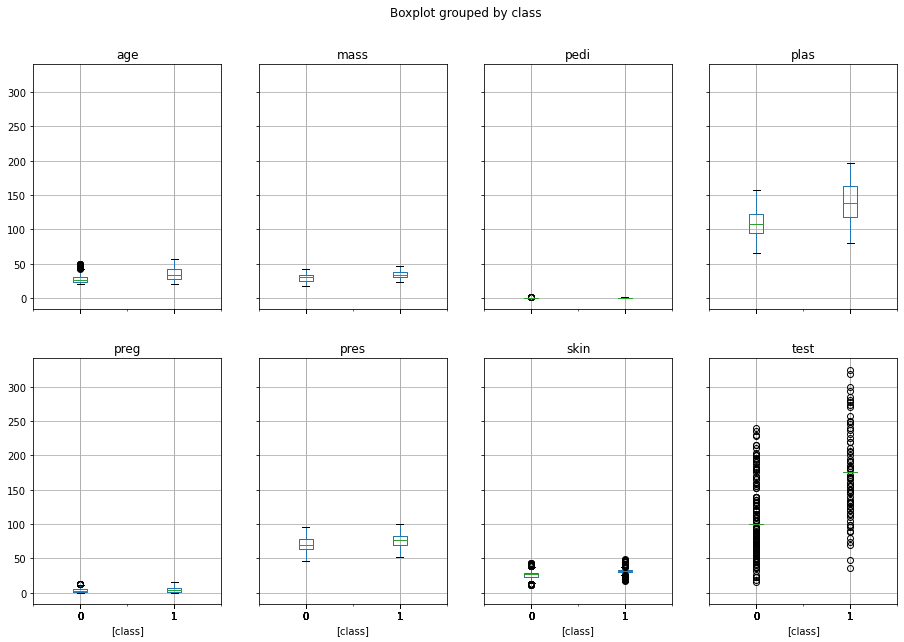

In [ ]:
# Do a boxblot to check for the impact on outliers. New outliers will appear because we replaced outliers with central values
# That would have reduced the standard deviations leading to appearance of new outlier datapoints
# Compare the outlier range before it was fixed with after it was fixed

final_pima_df.boxplot(by = 'class', layout=(2,4), figsize=(15, 10))

In [ ]:
pima_df_train, pima_df_test, y_train, y_test = train_test_split(final_pima_df.iloc[:,0:8] , final_pima_df.iloc[:,8] , test_size=0.30, random_state=1)

In [ ]:
dt_model = DecisionTreeClassifier(criterion = 'entropy', max_depth=3)
dt_model.fit(pima_df_train, y_train)
y_predict = dt_model.predict(pima_df_train)

In [ ]:
print(metrics.classification_report(y_train, y_predict))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       250
           1       0.89      0.82      0.85       125

    accuracy                           0.91       375
   macro avg       0.90      0.88      0.89       375
weighted avg       0.91      0.91      0.91       375



# Statistical Feature Selection Techniques

### statistical tests do not work on -ve values on input X.... we cannot run it on the z scored data

In [ ]:
# Feature Extraction with Univariate Statistical Tests (Chi-squared for classification)

import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2


X = final_pima_df.values[:,0:8]  # final pima dataframe after fixing the outliers and missing values
Y = final_pima_df.values[:,8]


# feature extraction
test = SelectKBest(score_func=chi2, k=3)    #using Chi-Square analysis for identifying features with influence on target
fit = test.fit(X, Y)     # This line will assess strength of the relation between the features and the target


# summarize scores
np.set_printoptions(precision=3)   # contolling the decimal values in the print

features = fit.transform(X)     # Extract the identified features from the raw dataset (feature selection happens here)

In [ ]:
feature_score =  [(item, score)
                 for item, score in zip(final_pima_df.columns, fit.scores_)]

feature_score

# Most important attribute is "test" , "plas", "age", "skin"  - compare this with the pairplot after all treatment. 
# you should notice the importance visually too.

[('preg', 57.39192839603335),
 ('plas', 985.0924444750417),
 ('pres', 39.0727154990721),
 ('skin', 135.3668618078581),
 ('test', 5082.324543851637),
 ('mass', 74.38789600263839),
 ('pedi', 2.564447988339987),
 ('age', 182.86711682876665)]

In [ ]:
# SelectKBest based on Chi-Square chose "Plas", "Skin", Test" and "Age"  as top features

# Recursive Feature Elimination using SKlearn RFE

In [ ]:
# Feature Extraction with RFE
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
# feature extraction for a given algorithm

model = DecisionTreeClassifier()
#model = LogisticRegression()
rfe = RFE(model, 3)   # use recursive feature elimination to find the 3 top features that give the best logistic regression 
fit = rfe.fit(X, Y)
print(("Num Features: %d"), fit.n_features_)
print(("Selected Features: %s") % fit.support_)
print(("Feature Ranking: %s") % fit.ranking_)   #Most useful features are given rank 1

Num Features: %d 3
Selected Features: [False  True False  True  True False False False]
Feature Ranking: [6 1 5 1 1 3 4 2]


C:\Users\Mukesh Rao\anaconda3\lib\site-packages\sklearn\utils\validation.py:70: FutureWarning: Pass n_features_to_select=3 as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


In [ ]:
feature_rank =  [(item, rank)
                 for item, rank in zip(final_pima_df.columns, fit.ranking_)]

feature_rank

# Note: The feature importance is not the same we got earlier. This shows that importance of features also depends on which 
# ML algorithm we use to evaluate. Features important for decision tree may not be the same as features important for Logistic

[('preg', 6),
 ('plas', 1),
 ('pres', 5),
 ('skin', 1),
 ('test', 1),
 ('mass', 3),
 ('pedi', 4),
 ('age', 2)]

In [ ]:
# RFE chose "Skin", "Age" and "Pedi"  as top features followed by "BMI" and "Test"

# Ensemble to select features...

In [ ]:
# Feature Importance with Extra Trees Classifier

from sklearn.ensemble import ExtraTreesClassifier as ET  #extremely randomized tree classifier.


# feature extraction
model = ET()
model.fit(X, Y)
print(model.feature_importances_)

[0.051 0.159 0.054 0.116 0.385 0.081 0.059 0.094]


In [ ]:
feature_score =  [(item, score)
                 for item, score in zip(final_pima_df.columns, model.feature_importances_)]

feature_score

# Important features - "Test" , "Plas" , "Skin"

[('preg', 0.05118375800187259),
 ('plas', 0.15932533387445877),
 ('pres', 0.054147667182555016),
 ('skin', 0.11592237960276543),
 ('test', 0.38474818874267963),
 ('mass', 0.08117343573683056),
 ('pedi', 0.05910820146292262),
 ('age', 0.09439103539591533)]

# mlextend forward and backward feature selection 

## Forward feature selection 

In [ ]:
#!pip install mlxtend   #not part of SKLearn. Has to be installed separately
from mlxtend.feature_selection import SequentialFeatureSelector as sfs

In [ ]:
sfs1 = sfs(model,k_features=3,forward=True,floating=False,verbose=2,scoring='f1',cv=5)  # looking for 3 best features

In [ ]:
colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']
sfs1 = sfs1.fit(X, Y, custom_feature_names=colnames)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   8 out of   8 | elapsed:    3.1s finished

[2021-10-24 09:33:21] Features: 1/3 -- score: 0.798511864267013[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   7 out of   7 | elapsed:    2.6s finished

[2021-10-24 09:33:23] Features: 2/3 -- score: 0.8511443668584487[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed:    2.3s finished

[2021-10-24 09:33:26] Features: 3/3 -- score: 0.8644343496921272

In [ ]:
 sfs1.subsets_   #Note: "Skin" , "Test", "Plasma" stand.... Compare this with the pairplot

{1: {'feature_idx': (4,),
  'cv_scores': array([0.725, 0.783, 0.892, 0.725, 0.868]),
  'avg_score': 0.798511864267013,
  'feature_names': ('test',)},
 2: {'feature_idx': (3, 4),
  'cv_scores': array([0.812, 0.838, 0.93 , 0.8  , 0.877]),
  'avg_score': 0.8511443668584487,
  'feature_names': ('skin', 'test')},
 3: {'feature_idx': (3, 4, 7),
  'cv_scores': array([0.877, 0.776, 0.886, 0.895, 0.889]),
  'avg_score': 0.8644343496921272,
  'feature_names': ('skin', 'test', 'age')}}

# Backward selection 

In [ ]:
sfs2 = sfs(model,k_features="best",forward=False,floating=False,verbose=2,scoring='f1',cv=5)

In [ ]:
colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']

sfs2 = sfs2.fit(X, Y , custom_feature_names=colnames)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   8 out of   8 | elapsed:    3.5s finished

[2021-10-24 09:33:34] Features: 7/1 -- score: 0.8810111527982946[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   7 out of   7 | elapsed:    2.7s finished

[2021-10-24 09:33:37] Features: 6/1 -- score: 0.8859513398447876[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed:    2.0s finished

[2021-10-24 09:33:39] Features: 5/1 -- score: 0.8857277376921557[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 

In [ ]:
 sfs2.subsets_

{8: {'feature_idx': (0, 1, 2, 3, 4, 5, 6, 7),
  'cv_scores': array([0.889, 0.824, 0.861, 0.865, 0.895]),
  'avg_score': 0.8666262237469669,
  'feature_names': ('preg',
   'plas',
   'pres',
   'skin',
   'test',
   'mass',
   'pedi',
   'age')},
 7: {'feature_idx': (0, 1, 3, 4, 5, 6, 7),
  'cv_scores': array([0.901, 0.824, 0.882, 0.877, 0.921]),
  'avg_score': 0.8810111527982946,
  'feature_names': ('preg', 'plas', 'skin', 'test', 'mass', 'pedi', 'age')},
 6: {'feature_idx': (0, 1, 3, 4, 5, 7),
  'cv_scores': array([0.899, 0.873, 0.886, 0.853, 0.919]),
  'avg_score': 0.8859513398447876,
  'feature_names': ('preg', 'plas', 'skin', 'test', 'mass', 'age')},
 5: {'feature_idx': (0, 3, 4, 5, 7),
  'cv_scores': array([0.901, 0.829, 0.886, 0.921, 0.892]),
  'avg_score': 0.8857277376921557,
  'feature_names': ('preg', 'skin', 'test', 'mass', 'age')},
 4: {'feature_idx': (3, 4, 5, 7),
  'cv_scores': array([0.873, 0.824, 0.901, 0.909, 0.892]),
  'avg_score': 0.8798320200142902,
  'feature_names'

# Feature Engineering

In [ ]:
def genbmi(row):
    if row["mass"] < 0:
        return(0)
    else:
        return(1)

def gentest(row):
    if row["test"] < 0:
        return(0)
    else:
        return(1)



In [ ]:


colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']


# converting to dataframe to be able to use "assign" function 

X = pd.DataFrame(final_pima_df.values[:,0:8] , columns=colnames)
Y = pd.DataFrame(final_pima_df.values[:,8],columns =['class'])

In [ ]:
X.head()

,preg,plas,pres,skin,test,mass,pedi,age
0,0.0,97.0,64.0,36.0,100.0,36.8,0.6000,25.0
1,1.0,116.0,70.0,28.0,100.0,27.4,0.2040,21.0
2,2.0,106.0,64.0,35.0,119.0,30.5,0.3295,34.0
3,0.0,123.0,88.0,37.0,100.0,35.2,0.1970,29.0
4,1.0,143.0,84.0,23.0,100.0,42.4,0.3295,22.0


In [ ]:
X = pd.DataFrame(zscore(X) , columns = colnames)

In [ ]:
X_temp = X.copy()
X_temp['class'] = Y

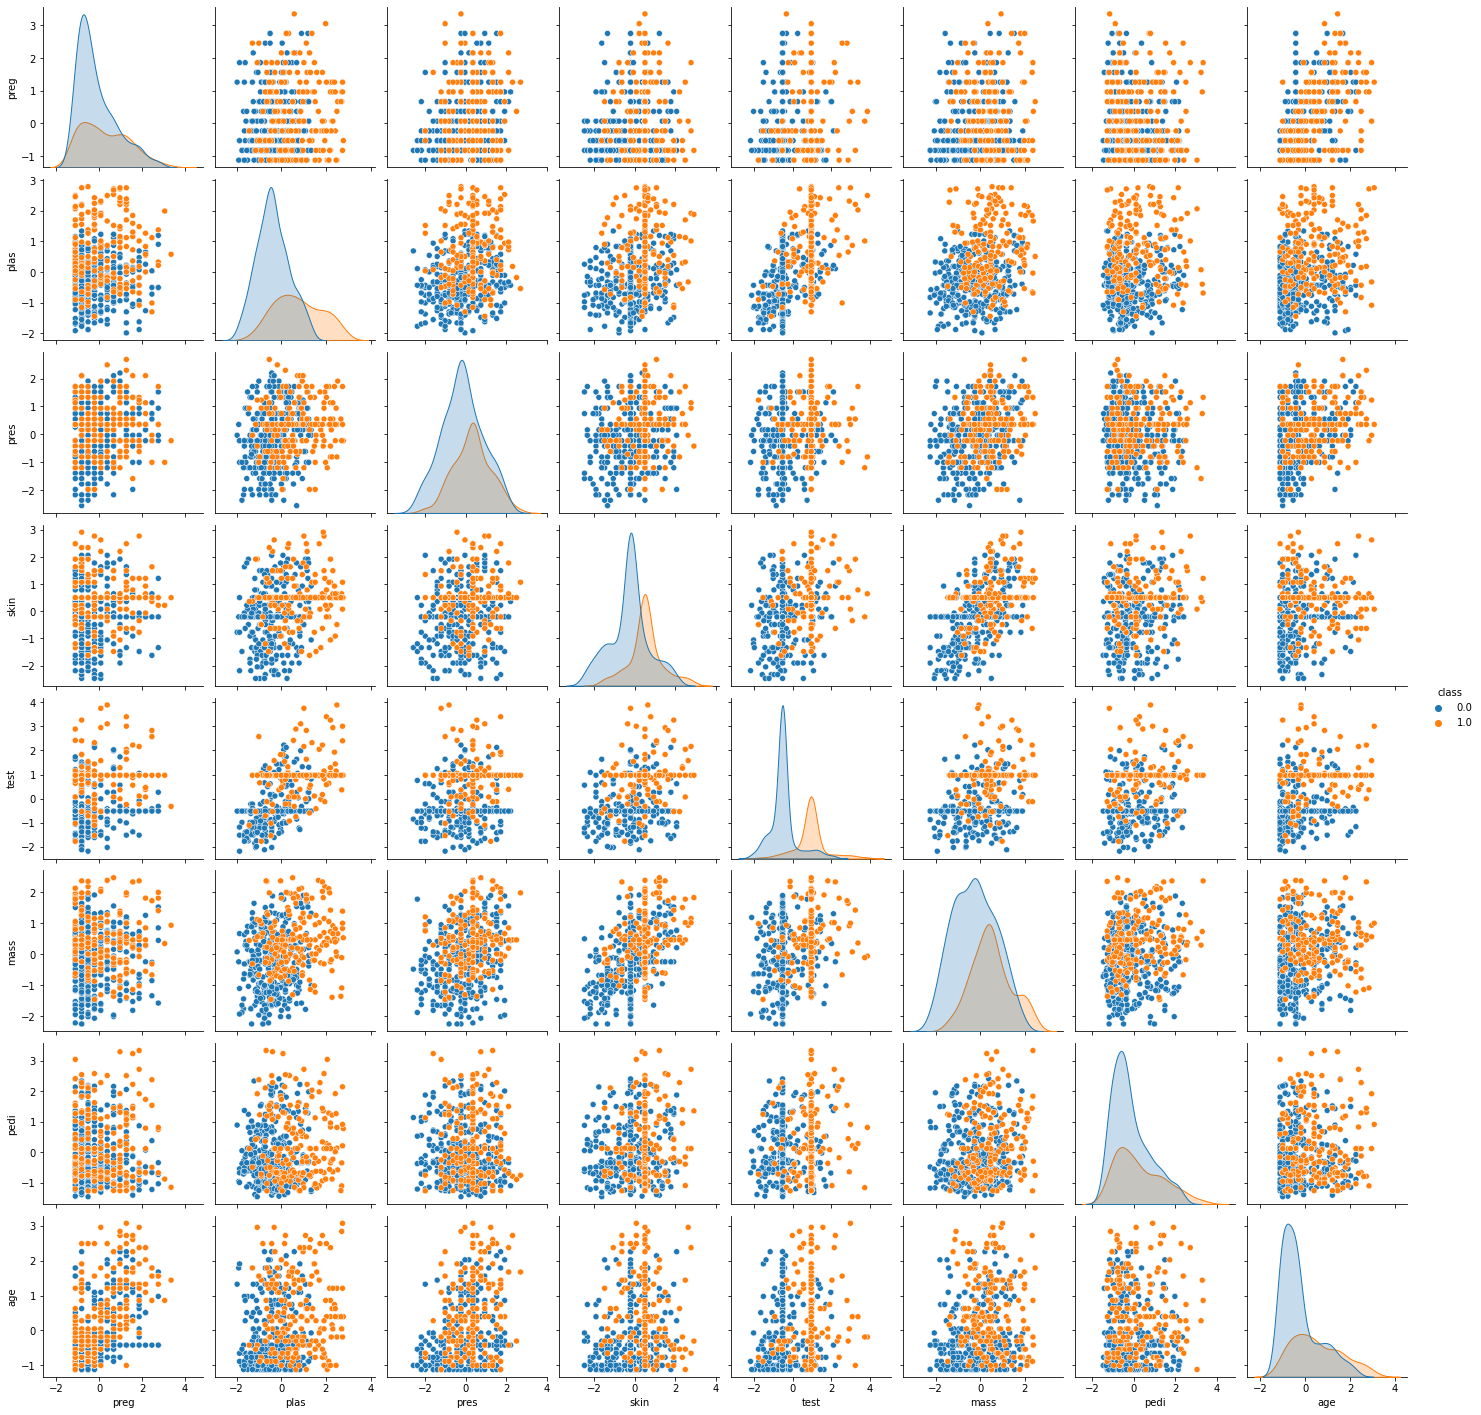

In [ ]:
sns.pairplot(data=X_temp, diag_kind = 'kde', hue = 'class')  # Check the distribution after the imputation

In [ ]:
# Generating synthetic features based on observation on pairplot

X= X.assign(enggbmi=X.apply(genbmi, axis=1))
X= X.assign(gentest=X.apply(gentest, axis=1))

In [ ]:
X.head()

,preg,plas,pres,skin,test,mass,pedi,age,enggbmi,gentest
0,-1.121017,-0.827540,-0.811451,1.071012,-0.517052,0.885969,0.892430,-0.654289,1,0
1,-0.822709,-0.141922,-0.227989,-0.063094,-0.517052,-0.694758,-0.913328,-1.120120,0,0
2,-0.524401,-0.502774,-0.811451,0.929249,-0.145094,-0.173455,-0.341048,0.393831,0,0
3,-1.121017,0.110675,1.522399,1.212776,-0.517052,0.616909,-0.945247,-0.188458,1,0
4,-0.822709,0.832379,1.133424,-0.771910,-0.517052,1.827678,-0.341048,-1.003662,1,0


In [ ]:
# Creating decision tree model on the data

from sklearn.tree import DecisionTreeClassifier


dt_model = DecisionTreeClassifier(criterion = 'entropy' , max_depth=4 )
dt_model.fit(X, Y)

DecisionTreeClassifier(criterion='entropy', max_depth=4)

In [ ]:
y_predict = dt_model.predict(X)
print(metrics.classification_report(Y, y_predict))

              precision    recall  f1-score   support

         0.0       0.93      0.95      0.94       354
         1.0       0.90      0.86      0.88       183

    accuracy                           0.92       537
   macro avg       0.92      0.90      0.91       537
weighted avg       0.92      0.92      0.92       537



# One single train test is not reliable. Let us do KFold Cross Validation and assess the class level metrics

In [ ]:

from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_validate
from statistics import mean, stdev

score_dict = {'accuracy' : make_scorer(accuracy_score), 
           'precision' : make_scorer(precision_score),
           'recall' : make_scorer(recall_score), 
           'f1_score' : make_scorer(f1_score)}

In [ ]:
num_folds = 10


skf = StratifiedKFold(n_splits=num_folds)    # Do not take simple KFold on imbalanced datasets

results = cross_validate(dt_model, X, Y, cv=skf , scoring=score_dict)


In [ ]:

for key in results:
    print(key , mean(results[key]) , stdev(results[key]) )
    print(''.format(key, mean(results[key])*100.0, stdev(results[key])*100.0))



fit_time 0.003306126594543457 0.0004961299672337876

score_time 0.003564310073852539 0.0010077532388772772

test_accuracy 0.8938504542278127 0.03725898102483905

test_precision 0.8516488413547237 0.07468447630055323

test_recall 0.8412280701754385 0.09195998113239758

test_f1_score 0.8424675522043943 0.05911926492898914



In [ ]:
# These are precision, recall and f1 score for the positive (diabetic) class. Compare these with the same metrics for the same
# class when model is created on data where missing value and outlier are blindly replaced with mean / median ignoring the class

In [ ]:
X['class'] = Y

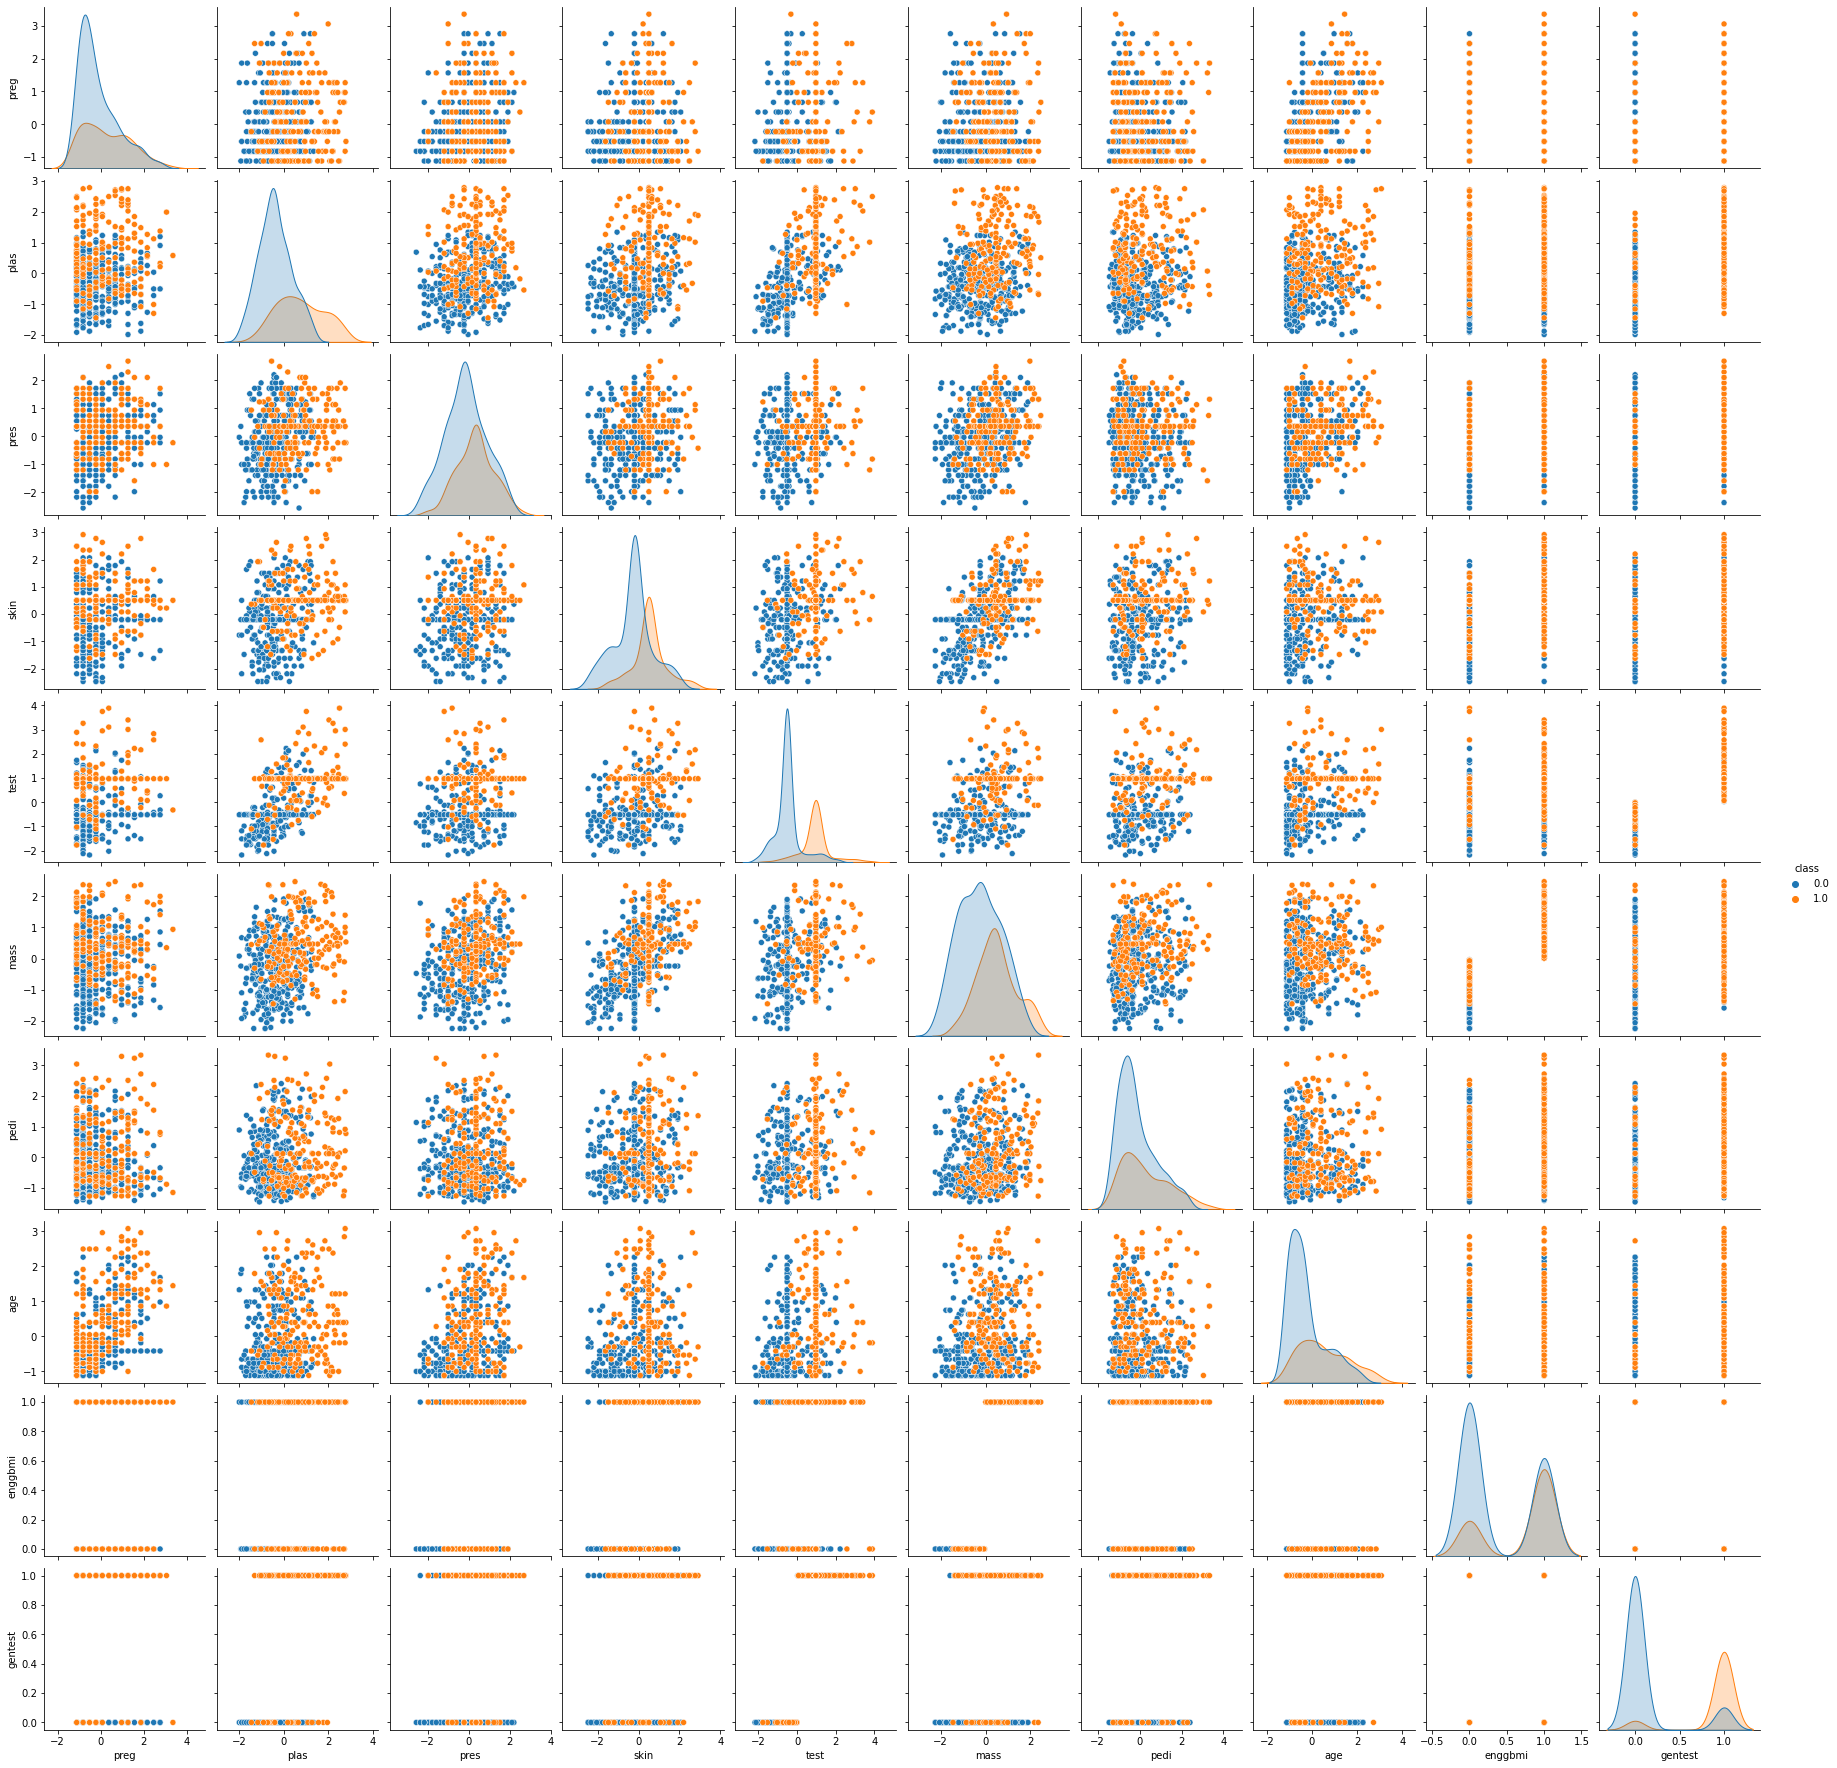

In [ ]:
sns.pairplot(data=X, diag_kind = 'kde', hue = 'class')  # Check the distribution after the imputation